In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

In [ ]:
iris = load_iris()
X = iris.data[:100, :2]
y = iris.target[:100]
print("X'in boyutu:", X.shape)
print("y'nin boyutu:", y.shape)

X'in boyutu: (100, 2)
y'nin boyutu: (100,)


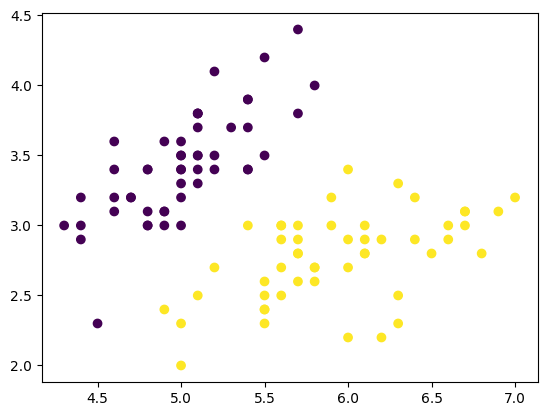

In [ ]:
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.show()

In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))
print("sigmoid(5) sonucu:", sigmoid(5))


sigmoid(5) sonucu: 0.9933071490757153


In [ ]:
def log_likelihood(w, x, y):
    n = len(y)
    s = sigmoid(x @ w)
    epsilon = 1e-15
    loss = 1/n * np.sum(y * np.log(s + epsilon) + (1 - y) * np.log(1 - s + epsilon))
    return -loss
def gradient(w, x, y):
    n = len(y)
    s = sigmoid(x @ w)
    grad = 1/n * x.T @ (s - y)
    return grad

In [ ]:
temp = np.ones((X.shape[0], 1))
print("temp boyutu:", temp.shape)

X_yeni = np.concatenate((temp, X), axis=1)
print("X_yeni boyutu:", X_yeni.shape)

w = np.zeros(X_yeni.shape[1])
print("Başlangıç ağırlıkları (w):", w)

temp boyutu: (100, 1)
X_yeni boyutu: (100, 3)
Başlangıç ağırlıkları (w): [0. 0. 0.]


In [ ]:
n_iteration = 1000
kayip = []
learning_rate = 0.5

for i in range(n_iteration):
    g = gradient(w, X_yeni, y)
    k = log_likelihood(w, X_yeni, y)
    w = w - learning_rate * g
    kayip.append(k)

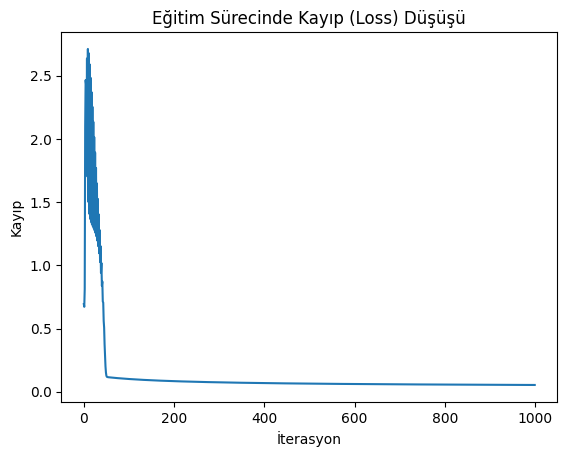

Eğitim bitti. Bulunan son ağırlıklar: [-2.01040375  5.17234382 -8.39543357]


In [ ]:
plt.plot(kayip)
plt.title("Eğitim Sürecinde Kayıp (Loss) Düşüşü")
plt.xlabel("İterasyon")
plt.ylabel("Kayıp")
plt.show()

print("Eğitim bitti. Bulunan son ağırlıklar:", w)